# Kết quả, cảnh báo và giới hạn
Đọc các file đã chốt để đối chiếu với Word. Notebook này không gọi huấn luyện hoặc tìm cấu hình theo TEST.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'appliances_core.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import appliances_core as v1
from v2 import core


In [2]:
r = json.loads((ROOT/'out_v2/results.json').read_text(encoding='utf-8'))
v = json.loads((ROOT/'out_v2/verification.json').read_text(encoding='utf-8'))
print('Phiên được chọn:', r['version'])
display(pd.DataFrame([{'phuong_an': k, **item['metrics']} for k, item in r['finalists'].items()]))
display(v['counts'])

Phiên được chọn: v2


,phuong_an,n,mae,rmse,bias,high_n,high_episodes,high_mae,high_rmse,high_bias,high_underprediction_rate
0,v1,3847,146.776743,312.053208,-86.453772,120,21,1201.766809,1300.233556,-1196.846856,0.983333
1,selected,3847,153.545609,296.280938,-26.909727,120,21,905.608308,1052.750748,-879.523358,0.933333
2,best_multi,3847,153.545609,296.280938,-26.909727,120,21,905.608308,1052.750748,-879.523358,0.933333
3,best_direct,3847,161.164481,301.470795,-19.325514,120,21,927.543294,1063.057357,-916.042736,0.966667
4,lstm,3847,151.762024,322.428054,-96.433643,120,21,1243.675926,1327.481408,-1243.675926,1.000000


{'tp': 82, 'fp': 349, 'fn': 38, 'tn': 3378}

In [3]:
pred = pd.read_csv(ROOT/'out_v2/test_predictions.csv')
actual = pred[[f'actual_{i}m' for i in range(10, 61, 10)]].sum(axis=1)
np.testing.assert_allclose(actual, pred.actual_hour_total)
mae = np.abs(actual-pred.selected_hour_prediction).mean()
np.testing.assert_allclose(mae, r['selected']['mae'])
print('MAE được tính lại từ CSV:', mae)
display(pred[['issue_time','actual_hour_total','point_hour_total','selected_hour_prediction','p90','upper_cal','alert']].head())

MAE được tính lại từ CSV: 153.5456089539833


,issue_time,actual_hour_total,point_hour_total,selected_hour_prediction,p90,upper_cal,alert
0,2016-05-01 00:00:00,320.0,302.636034,302.636034,343.156932,354.060605,False
1,2016-05-01 00:10:00,310.0,320.657688,320.657688,343.467193,354.370866,False
2,2016-05-01 00:20:00,320.0,309.473238,309.473238,342.478139,353.381812,False
3,2016-05-01 00:30:00,320.0,305.329397,305.329397,340.957966,351.861639,False
4,2016-05-01 00:40:00,320.0,313.675978,313.675978,361.155140,372.058812,False


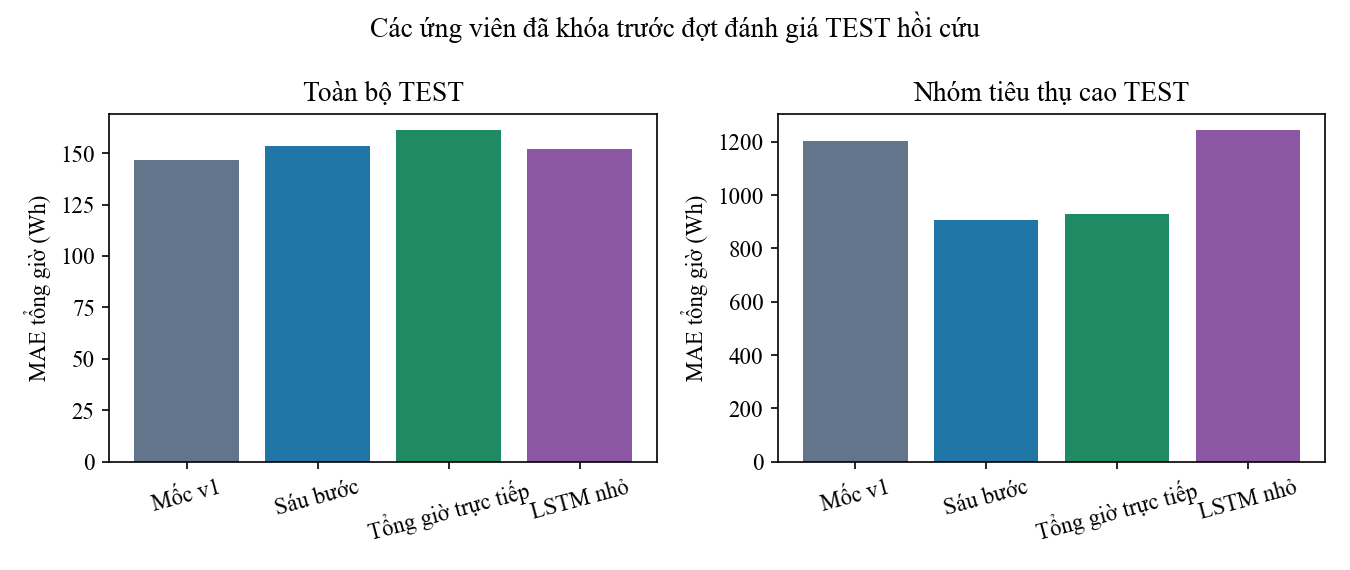

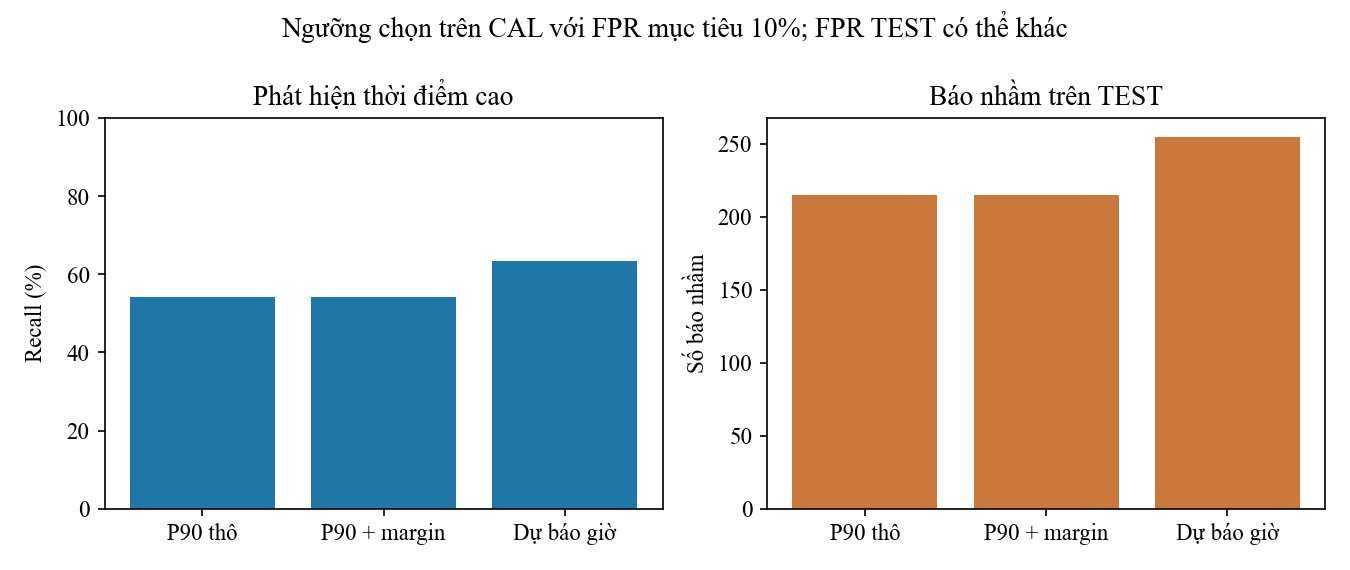

In [4]:
display(Image(filename=str(ROOT/'out_v2/figures/f_v2_models.png')))
display(Image(filename=str(ROOT/'out_v2/figures/f_v2_policies.png')))

## Cần diễn giải đúng
Giảm MAE là giảm sai số dự báo. Chưa có số đo tiết kiệm điện hoặc tiền điện, tải điều khiển được hay nghiệm thu người dùng. Các cửa sổ tổng giờ chồng lấn; lead của cụm dự báo không đồng nghĩa báo trước thời điểm bật thiết bị. Chưa có dữ liệu ngoài để xác nhận tổng quát.

In [5]:
display(pd.DataFrame(r['robustness']))
display(r['bootstrap'])
display(r['system'])

,scenario,replicates,mae,fp,fn,coverage
0,noise=0.1,5,156.124717,341.6,35.0,0.846894
1,dropout=0.1,5,155.831483,350.0,37.0,0.827294
2,meter_scale=0.9,1,161.383859,284.0,46.0,0.720821
3,meter_scale=1.1,1,166.000103,385.0,28.0,0.820639


{'block': 144,
 'replicates': 1000,
 'mae_percentile95': [127.28758809644833, 182.56700425468938],
 'gain_percent_percentile95': [-10.89266119944015, 0.7512435373955657],
 'scope': 'Descriptive paired block resampling; frozen models; overlapping targets; not an external validation'}

{'model_bytes': 5733179,
 'latency_n': 200,
 'p50_ms': 110.8886999936658,
 'p95_ms': 178.05228499710205,
 'scope': 'Loaded model; validation + features + prediction; excludes model loading, file I/O, SQLite, UI'}